# Lo que el motor no explica con sus valores de fábrica: los a priori de una calibración bayesiana, la respuesta del motor a ellos y la forma de su error

**Pregunta:** ¿Qué dejan sin explicar los valores de fábrica del motor en los diez muestreos del HP500, cuáles de sus ocho escalares ajustados pueden mover la respuesta, y qué forma de error debe agregar una calibración bayesiana a su alrededor?

- **Nivel:** 1, fundamentos
- **Requisitos previos:** el notebook 02 del tema 05 y los notebooks 01 y 02 del tema 06
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir cuáles ocho escalares del motor del chancador trata como incógnitas una calibración bayesiana, con el valor con que viene cada uno y el ancho de su a priori;
- correr el motor con valores de los escalares distintos de los de fábrica, y medir cuál escalar mueve el tonelaje y cuál mueve la potencia;
- sortear de los a priori, correr el motor en cada sorteo, y decir si los valores medidos caen dentro de la banda resultante antes de haber usado ningún muestreo;
- describir la parte del error del motor que es función de la abertura y del tamaño de alimentación, que es la parte para la que sirve un término de discrepancia.

## Preparación

Numpy y matplotlib; el motor y las definiciones de la calibración vienen del pipeline.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones traen el lector de muestreos, el motor con su constructor del punto de operación de un muestreo, las funciones de error de CrusherCal, y el módulo que guarda los a priori de CrusherBayes.

In [1]:

# Imprima las versiones de las herramientas de este notebook, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb, loo
from pipeline.model.crusher import evaluate, operating_from_survey
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietarios: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas están transcritas de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`. Cada muestreo da la abertura de descarga, el f80 de alimentación, el caudal y la potencia del motor; el motor toma los dos primeros como entradas y los dos últimos son contra lo que se lo juzga.

La celda lee los muestreos y convierte cada uno en el punto de operación del motor.

In [2]:

# Los diez muestreos y el punto de operación de cada uno (la abertura y el f80 de alimentación es todo
# lo que varía)
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
tph = np.array([s.feed_tph for s in surveys])
kw = np.array([s.power_kw for s in surveys])
ops = [operating_from_survey(c, f) for c, f in zip(css, f80)]
text = (
    'muestreos: {} | abertura {:.0f} a {:.0f} mm | f80 de '
    'alimentación {:.0f} a {:.0f} mm'
)
print(text.format(len(surveys), css.min(), css.max(), f80.min(), f80.max()))


muestreos: 10 | abertura 38 a 55 mm | f80 de alimentación 47 a 140 mm


## Método

**Paso 1, el motor de fábrica.** Calibrar es mover algunos números de un modelo hasta que concuerde con los datos. La vía HP500 del motor toma sus números de Rocha et al. (2024): una base de capacidad para el tonelaje, un índice de trabajo de Bond para la energía, y la pendiente y la potencia de vacío de la forma de potencia por corriente del artículo (`Pc = zeta Pd + Pn`). La celda corre el motor con esos valores sobre los diez muestreos, sin ajustarlo a ellos, y compara su tonelaje y su potencia con los medidos: este es el error desde el que parte cualquier calibración.

In [3]:

# El motor con los valores de fábrica, en cada muestreo, frente al tonelaje y la potencia medidos
shipped = [evaluate(op) for op in ops]
engine_tph = np.array([r.throughput_tph for r in shipped])
engine_kw = np.array([r.power_kw for r in shipped])
print('muestreo  t/h medido  t/h motor  kW medido  kW motor')
for k in range(len(ops)):
    print(f"{k + 1:6d} {tph[k]:13.0f} {engine_tph[k]:11.0f} {kw[k]:12.0f} {engine_kw[k]:10.0f}")
text = (
    'MAPE {:.2f} % y sesgo medio {:+.1f} t/h en el tonelaje; MAPE '
    '{:.2f} % y sesgo medio {:+.1f} kW en la potencia'
)
print(text.format(loo.mape(tph, engine_tph), np.mean(engine_tph - tph),
                  loo.mape(kw, engine_kw), np.mean(engine_kw - kw)))


muestreo  t/h medido  t/h motor  kW medido  kW motor
     1          1639        1209          209        408
     2          1267        1209          212        414
     3          1240        1107          262        402
     4          1034        1107          349        403
     5          1124        1107          325        415
     6           813         970          355        399
     7          1050         936          306        365
     8          1138        1039          325        387
     9           820         970          350        398
    10          1334        1226          187        419
MAPE 11.55 % y sesgo medio -57.9 t/h en el tonelaje; MAPE 47.58 % y sesgo medio +113.1 kW en la potencia


El tonelaje es cercano, con un MAPE de 11.55 por ciento y un sesgo medio de -57.9 t/h, pero la potencia no: un MAPE de 47.58 por ciento con el motor +113 kW sobre la planta en promedio. La potencia del motor está en una banda estrecha, de 365 a 419 kW, mientras la potencia medida va de 187 a 355 kW, así que no solo está desplazada sino plana donde la planta no lo está. Ese es el error de partida. Para calibrarlo hay que decir qué se puede mover.

**Paso 2, las incógnitas y sus a priori.** CrusherBayes trata ocho escalares del motor como incógnitas (`cb.PRIORS`), cada uno con un a priori centrado en el valor con que viene el motor: la base de capacidad `q_ref_tph`, el índice de trabajo de Bond `wi_kwh_t`, la pendiente `zeta` y la potencia de vacío `pn_kw` de la forma de potencia, un multiplicador de cada una de las dos constantes ajustadas K1 y K2 de la curva de clasificación que dependen del tamaño (`k1_scale`, `k2_scale`), el exponente de clasificación `k3`, y un desplazamiento de la constante 64 de la relación de t10 (`t10_shift_pct`). Un a priori es una afirmación de lo plausible antes de mirar los muestreos; los anchos aquí son elecciones débilmente informativas en torno a los valores del artículo, no rangos publicados, y la ficha del método en el pipeline lo dice. La celda imprime el valor nominal, la desviación estándar del a priori en la escala natural y sus límites.

In [4]:

# Los ocho escalares del motor: valor nominal, desviación estándar del a priori en su escala natural y
# sus límites
print((
    'escalar          unidad                 nominal   sd a priori  '
    'límite inf.  límite sup.'
))
for p in cb.PRIORS:
    print(f"{p.name:15s} {p.unit:20s} {p.nominal:9.2f} {cb.prior_sd_natural(p):10.3f} {p.lo:12.2f} {p.hi:12.2f}")
text = (
    'mediana del ruido: {:.0f} t/h y {:.0f} kW; sd a priori de la '
    'discrepancia por unidad estandarizada: {:.0f} t/h y {:.0f} kW'
)
print(text.format(cb.NOISE_MEDIAN["tph"], cb.NOISE_MEDIAN["kW"], cb.DISCREPANCY_SD["tph"], cb.DISCREPANCY_SD["kW"]))


escalar          unidad                 nominal   sd a priori  límite inf.  límite sup.
q_ref_tph       t/h                     647.00    167.010         5.70         7.24
wi_kwh_t        kWh/t                     9.00      1.516         1.61         2.64
zeta            -                         1.30      0.305        -0.69         0.92
pn_kw           kW                      110.00     47.853         0.00       300.00
k1_scale        -                         1.00      0.152        -0.69         0.69
k2_scale        -                         1.00      0.152        -0.69         0.69
k3              -                         2.30      0.489         1.00         4.00
t10_shift_pct   t10 percentage points      0.00      3.991       -15.00        15.00
mediana del ruido: 60 t/h y 15 kW; sd a priori de la discrepancia por unidad estandarizada: 140 t/h y 36 kW


Hay dos incógnitas más que no son escalares del motor: un nivel de ruido para cada objetivo, y el tamaño de una discrepancia agregada a cada uno. Las medianas y desviaciones estándar impresas son sus a priori. La pregunta siguiente es cuáles de los ocho escalares podrían informar los muestreos, y se le puede hacer al motor antes de cualquier muestreo. La celda mueve un escalar a la vez una desviación estándar a priori, dejando el resto en su valor nominal, corre el motor en los diez muestreos e informa cuánto se mueven en promedio el tonelaje y la potencia.

In [5]:

# Mueva cada escalar una desviación estándar a priori, solo, y vea cuánto se mueven las salidas del
# motor en los diez muestreos
sd = np.array([p.sd for p in cb.PRIORS])
centre = cb.nominal_theta()
effect = np.zeros((cb.N_ENGINE, 2))
for i in range(cb.N_ENGINE):
    theta = centre.copy()
    theta[i] += sd[i]
    moved = [evaluate(op, cb.scalars_of(theta)) for op in ops]
    effect[i, 0] = np.mean([abs(r.throughput_tph - b) for r, b in zip(moved, engine_tph)])
    effect[i, 1] = np.mean([abs(r.power_kw - b) for r, b in zip(moved, engine_kw)])
print('escalar          cambio medio en t/h   cambio medio en kW')
for p, (d_tph, d_kw) in zip(cb.PRIORS, effect):
    print(f"{p.name:15s} {d_tph:18.1f} {d_kw:20.1f}")


escalar          cambio medio en t/h   cambio medio en kW
q_ref_tph                    309.0                 82.7
wi_kwh_t                       0.0                 53.9
zeta                           0.0                 75.3
pn_kw                          0.0                 50.0
k1_scale                       0.0                 31.0
k2_scale                       0.0                 21.0
k3                             0.0                  9.9
t10_shift_pct                  0.0                  3.9


La figura muestra las dos columnas como barras, un par por escalar.

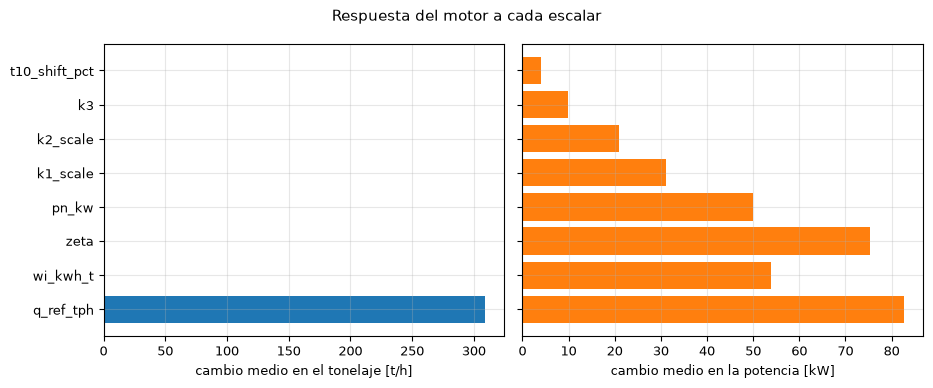

In [6]:

# La respuesta del motor a una desviación estándar a priori de cada escalar
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
labels = [p.name for p in cb.PRIORS]
axes[0].barh(labels, effect[:, 0], color="tab:blue")
axes[1].barh(labels, effect[:, 1], color="tab:orange")
axes[0].set_xlabel('cambio medio en el tonelaje [t/h]')
axes[1].set_xlabel('cambio medio en la potencia [kW]')
fig.suptitle('Respuesta del motor a cada escalar')
fig.tight_layout()
plt.show()


Un solo escalar mueve el tonelaje: la base de capacidad `q_ref_tph` lo desplaza 309 t/h con una desviación estándar a priori, y los otros siete lo mueven a lo más 0.0 t/h, que es nada. La potencia la mueven siete de los ocho, con `zeta` (75 kW), `wi_kwh_t` (54 kW) y la base de capacidad (83 kW) arriba, luego `pn_kw` (50 kW), `k1_scale` (31), `k2_scale` (21), `k3` (10) y `t10_shift_pct` (4). La figura no dice si los datos pueden distinguir los escalares entre sí: varios escalares mueven la potencia en el mismo sentido por el mismo tamaño de producto, así que pueden compensarse. Dice lo que es necesario para que se aprenda un escalar, que mueva alguna salida medida, y que los últimos cuatro mueven la potencia un orden de magnitud menos que los tres primeros. El notebook 02 de este tema mide el resto.

**Paso 3, la verificación predictiva a priori.** Antes de que una calibración mire los muestreos, los a priori por sí solos implican una distribución de salidas del motor: se sortean los ocho escalares de sus a priori (una normal en torno al valor nominal, mantenida dentro de los límites del a priori, que verifica `cb.log_prior`), se corre el motor en cada sorteo sobre los diez muestreos, y se toman los percentiles 10 y 90 por muestreo. Un a priori sensato produce una banda que contiene las mediciones sin ser absurdamente ancha. La celda usa 200 sorteos y cuenta cuántos valores medidos caen dentro de su banda.

In [7]:

# Verificación predictiva a priori: 200 sorteos de los escalares, el motor corrido en cada uno, la
# banda de 80 por ciento por muestreo
rng = np.random.default_rng(1)
draws = []
while len(draws) < 200:
    theta = centre.copy()
    theta[:cb.N_ENGINE] += sd * rng.standard_normal(cb.N_ENGINE)
    if np.isfinite(cb.log_prior(theta)):
        draws.append(theta)
runs = [[evaluate(op, cb.scalars_of(theta)) for op in ops] for theta in draws]
prior_tph = np.array([[r.throughput_tph for r in run] for run in runs])
prior_kw = np.array([[r.power_kw for r in run] for run in runs])
lo_t, hi_t = np.percentile(prior_tph, [10, 90], axis=0)
lo_k, hi_k = np.percentile(prior_kw, [10, 90], axis=0)
inside_t = np.sum((tph >= lo_t) & (tph <= hi_t))
inside_k = np.sum((kw >= lo_k) & (kw <= hi_k))
print((
    'medido dentro de la banda a priori de 80 %: {:.0f} de 10 en el '
    'tonelaje y {:.0f} de 10 en la potencia'
).format(inside_t, inside_k))
print('ancho medio de la banda: {:.0f} t/h y {:.0f} kW'.format(np.mean(hi_t - lo_t), np.mean(hi_k - lo_k)))


medido dentro de la banda a priori de 80 %: 9 de 10 en el tonelaje y 6 de 10 en la potencia
ancho medio de la banda: 642 t/h y 313 kW


La figura traza la banda a priori de cada muestreo como una barra gris, el valor medido como un punto rojo y el motor de fábrica como una raya negra.

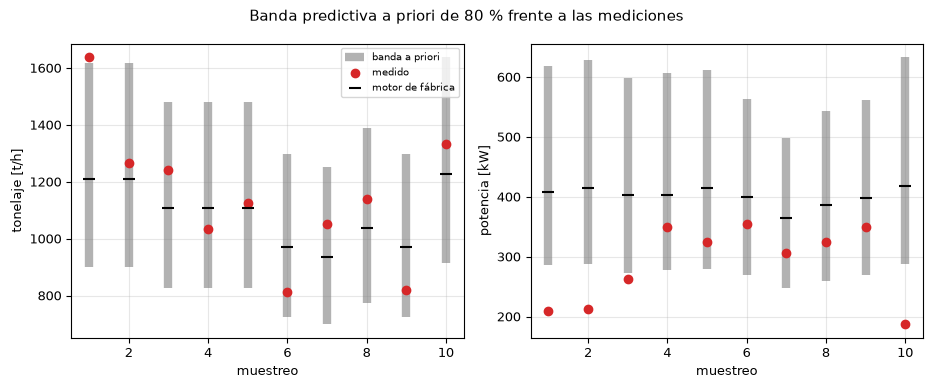

In [8]:

# La banda predictiva a priori de cada muestreo frente al valor medido
x = np.arange(1, len(ops) + 1)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, lo, hi, y, shipped_y, ylabel in ((axes[0], lo_t, hi_t, tph, engine_tph, 'tonelaje [t/h]'),
                                         (axes[1], lo_k, hi_k, kw, engine_kw, 'potencia [kW]')):
    ax.vlines(x, lo, hi, color="tab:grey", lw=6, alpha=0.6, label='banda a priori')
    ax.scatter(x, y, color="tab:red", zorder=3, label='medido')
    ax.scatter(x, shipped_y, color="black", marker="_", s=80, zorder=3, label='motor de fábrica')
    ax.set_xlabel('muestreo')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Banda predictiva a priori de 80 % frente a las mediciones')
fig.tight_layout()
plt.show()


La banda a priori contiene 9 de los 10 tonelajes medidos y 6 de las 10 potencias medidas, con un ancho medio de 642 t/h y 313 kW. Los a priori son entonces lo bastante anchos para no descartar lo que hizo la planta, que es para lo que sirve un a priori débilmente informativo, y para la potencia las bandas son casi tan anchas como el propio rango medido (168 kW), así que los a priori por sí solos dicen poco de qué muestreo consume más. La figura también muestra el motor de fábrica, las rayas negras, dentro de la banda del tonelaje y sobre la banda de la potencia en la mayoría de los muestreos. No muestra si los datos llevan a los escalares hacia una región que ajuste; eso lo hace el muestreo del a posteriori, y es el notebook siguiente.

**Paso 4, la forma de lo que queda.** El motor con cualesquiera valores de los escalares es una función suave de la abertura y del tamaño de alimentación, y lo mismo es la parte del comportamiento de la planta que un modelo físico omite. Un término de discrepancia, en la forma que le dieron Kennedy y O'Hagan (2001), es una función flexible agregada al modelo para llevar ese error estructurado, en lugar de forzar a los escalares a absorberlo. CrusherBayes usa su menor orden: una constante y una pendiente sobre la abertura estandarizada y una sobre el f80 de alimentación estandarizado, por objetivo. La celda regresa el residuo del motor de fábrica sobre exactamente ese plano, para ver cuánto del error tiene esa forma.

In [9]:

# El residuo del motor de fábrica regresado sobre la abertura y el f80 estandarizados, la forma de la
# discrepancia
mu = np.array([css.mean(), f80.mean()])
scale = np.array([css.std(), f80.std()])
design = cb.design(css, f80, mu, scale)
fitted = {}
for name, y, engine_y in (("tph", tph, engine_tph), ("kW", kw, engine_kw)):
    resid = y - engine_y
    coef, *_ = np.linalg.lstsq(design, resid, rcond=None)
    r_squared = 1 - np.sum((resid - design @ coef) ** 2) / np.sum((resid - resid.mean()) ** 2)
    fitted[name] = (resid, design @ coef)
    print((
    '{:5s} sd del residuo {:6.1f}: constante {:+7.1f}, abertura '
    '{:+7.1f}, f80 {:+7.1f} por desviación estándar, R cuadrado '
    '{:.2f}'
).format(name, resid.std(), coef[0], coef[1], coef[2], r_squared))


tph   sd del residuo  161.3: constante   +57.9, abertura  +116.0, f80   +68.1 por desviación estándar, R cuadrado 0.45
kW    sd del residuo   69.8: constante  -113.1, abertura   -64.5, f80    -5.5 por desviación estándar, R cuadrado 0.80


La figura traza, para cada objetivo, el residuo del motor de fábrica contra la abertura como puntos rojos y el plano ajustado evaluado en los mismos muestreos como cruces azules.

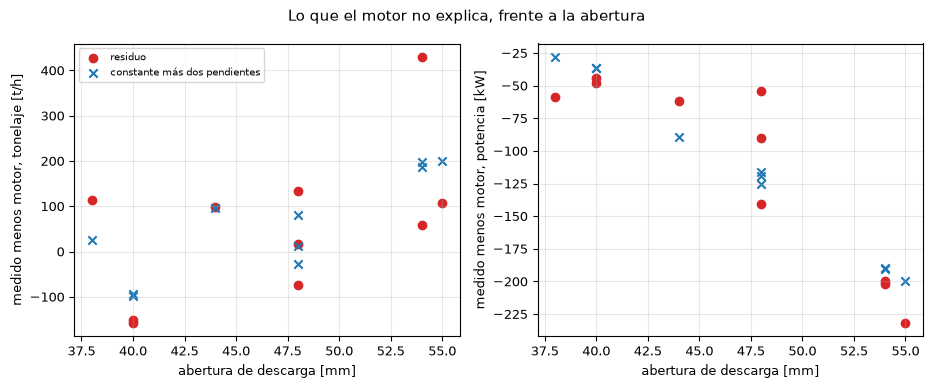

In [10]:

# El residuo del motor de fábrica frente a la abertura, con el plano de discrepancia ajustado
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
panels = (
    (axes[0], "tph", 'medido menos motor, tonelaje [t/h]'),
    (axes[1], "kW", 'medido menos motor, potencia [kW]'),
)
for ax, name, ylabel in panels:
    resid, plane = fitted[name]
    ax.scatter(css, resid, color="tab:red", label='residuo')
    ax.scatter(css, plane, color="tab:blue", marker="x", label='constante más dos pendientes')
    ax.set_xlabel('abertura de descarga [mm]')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Lo que el motor no explica, frente a la abertura')
fig.tight_layout()
plt.show()


El plano explica 0.80 de la varianza del residuo de potencia y 0.45 de la del residuo de tonelaje. En la potencia la pendiente de la abertura es -64 kW por desviación estándar, la del f80 es -6 kW y la constante es -113 kW, de modo que casi todo el error estructurado es la abertura: el motor no capta el alza de la potencia de la planta al cerrarse la abertura. En el tonelaje las pendientes son +116 t/h para la abertura y +68 t/h para el f80, un patrón más débil y menos limpio. Una regresión sobre diez puntos con tres coeficientes siempre ajusta algo del ruido, de modo que estos R cuadrado son optimistas y no son la afirmación: la afirmación es solo que el error tiene una forma que una función de bajo orden de la abertura y del f80 puede llevar, y ese es el argumento para agregar una discrepancia y para reajustarla sin cada muestreo retenido, lo que hacen los dos notebooks siguientes.

## Resultados

**Respuesta:** el motor de fábrica deja sin explicar su potencia y casi explica su tonelaje, solo uno de sus ocho escalares puede mover el tonelaje, y lo que sobra tiene la forma de una función de la abertura. Con sus valores de fábrica el motor tiene un MAPE de 11.55 por ciento en el tonelaje y 47.58 por ciento en la potencia, con la potencia +113 kW sobre la planta en promedio y plana entre 365 y 419 kW donde la planta va de 187 a 355 kW. Mover cada escalar una desviación estándar a priori desplaza el tonelaje 309 t/h solo por la base de capacidad, los otros siete 0.0 t/h o menos, y la potencia hasta 75 kW por `zeta`. Sorteados de sus a priori, los escalares dan una banda de 80 por ciento que contiene 9 de los 10 tonelajes medidos y 6 de las 10 potencias medidas, con anchos medios de 642 t/h y 313 kW. Un plano en la abertura y el f80 explica 0.80 del residuo de potencia (pendiente de la abertura -64 kW por desviación estándar) y 0.45 del residuo de tonelaje, una cifra dentro de la muestra sobre diez puntos que argumenta a favor de un término de discrepancia y no prueba nada sobre la habilidad fuera de la muestra.

## Resumen

Una calibración necesita tres cosas que el motor ya tiene o que este notebook construyó: un modelo que corra lo bastante rápido para llamarlo miles de veces, un conjunto de incógnitas con a priori lo bastante anchos para no excluir a la planta, y una imagen clara de lo que el modelo no puede explicar. El motor de fábrica explica el tonelaje y deja plana la potencia; un escalar controla lo primero y siete comparten lo segundo, varios de ellos por el mismo tamaño de producto; y la parte no explicada sigue a la abertura. El notebook siguiente muestrea el a posteriori de los ocho escalares y del ruido sobre los muestreos, y muestra cuáles de ellos mueven los datos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294